# Obesity Level Prediction using Machine Learning
**Google Colab notebook — ML Lab Project**

This notebook loads the UCI obesity dataset, preprocesses it, compares Logistic Regression, Decision Tree and Random Forest, and lets you enter a person's details to predict an obesity-level class.

**Important:** This is an educational prediction only, not a medical diagnosis. The dataset target is BMI-related, so the notebook compares:
- **Experiment A:** all available input features, including Height and Weight
- **Experiment B:** lifestyle/basic-demographic features, excluding Height and Weight

Run the cells from top to bottom.

## 1. Install and import libraries

In [2]:
!pip -q install pandas numpy scikit-learn matplotlib seaborn joblib

In [3]:
import io
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)
from joblib import dump

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Upload the dataset CSV
Upload `ObesityDataSet_raw_and_data_sinthetic.csv` (the filename may vary slightly).

In [4]:
uploaded = files.upload()
csv_name = next(name for name in uploaded.keys() if name.lower().endswith(".csv"))
df = pd.read_csv(io.BytesIO(uploaded[csv_name]))

print("Loaded file:", csv_name)
print("Original shape:", df.shape)
display(df.head())
print("\\nMissing values per column:")
display(df.isna().sum().to_frame("Missing values"))
print("\\nDuplicate rows:", df.duplicated().sum())

df = df.drop_duplicates().reset_index(drop=True)
TARGET = "NObeyesdad"

if TARGET not in df.columns:
    raise ValueError(f"Target column '{TARGET}' not found. Columns are: {df.columns.tolist()}")

print("Shape after removing duplicates:", df.shape)
print("Target classes:", sorted(df[TARGET].dropna().unique().tolist()))
print("Class counts:")
display(df[TARGET].value_counts().to_frame("Count"))

Saving ObesityDataSet_raw_and_data_sinthetic.csv to ObesityDataSet_raw_and_data_sinthetic.csv
Loaded file: ObesityDataSet_raw_and_data_sinthetic.csv
Original shape: (2111, 17)


,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


\nMissing values per column:


,Missing values
Gender,0
Age,0
Height,0
Weight,0
family_history_with_overweight,0
FAVC,0
FCVC,0
NCP,0
CAEC,0
SMOKE,0


\nDuplicate rows: 24
Shape after removing duplicates: (2087, 17)
Target classes: ['Insufficient_Weight', 'Normal_Weight', 'Obesity_Type_I', 'Obesity_Type_II', 'Obesity_Type_III', 'Overweight_Level_I', 'Overweight_Level_II']
Class counts:


,Count
NObeyesdad,
Obesity_Type_I,351
Obesity_Type_III,324
Obesity_Type_II,297
Overweight_Level_II,290
Normal_Weight,282
Overweight_Level_I,276
Insufficient_Weight,267


## 3. Prepare data and define preprocessing

In [5]:
X_all = df.drop(columns=[TARGET]).copy()
y = df[TARGET].copy()

# Experiment A: all features
X_all = X_all.copy()

# Experiment B: remove BMI-related measurements
columns_to_drop = [c for c in ["Height", "Weight"] if c in X_all.columns]
X_lifestyle = X_all.drop(columns=columns_to_drop).copy()

def make_preprocessor(X):
    numeric_cols = X.select_dtypes(include=["number"]).columns.tolist()
    categorical_cols = X.select_dtypes(exclude=["number"]).columns.tolist()

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])

    return ColumnTransformer([
        ("num", numeric_pipeline, numeric_cols),
        ("cat", categorical_pipeline, categorical_cols)
    ])

print("All-feature columns:", X_all.columns.tolist())
print("Removed for lifestyle-only experiment:", columns_to_drop)
print("Lifestyle-only columns:", X_lifestyle.columns.tolist())

All-feature columns: ['Gender', 'Age', 'Height', 'Weight', 'family_history_with_overweight', 'FAVC', 'FCVC', 'NCP', 'CAEC', 'SMOKE', 'CH2O', 'SCC', 'FAF', 'TUE', 'CALC', 'MTRANS']
Removed for lifestyle-only experiment: ['Height', 'Weight']
Lifestyle-only columns: ['Gender', 'Age', 'family_history_with_overweight', 'FAVC', 'FCVC', 'NCP', 'CAEC', 'SMOKE', 'CH2O', 'SCC', 'FAF', 'TUE', 'CALC', 'MTRANS']


## 4. Train and compare the three models
Both experiments use the same stratified 80:20 split settings. Each model gets a preprocessing pipeline fitted only on its training data.

In [6]:
def model_definitions():
    return {
        "Logistic Regression": LogisticRegression(max_iter=1000),
        "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
        "Random Forest": RandomForestClassifier(
            n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1
        )
    }

def run_experiment(X, y, experiment_name):
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
    )

    results = []
    fitted_models = {}

    for name, classifier in model_definitions().items():
        pipe = Pipeline([
            ("preprocessor", make_preprocessor(X_train)),
            ("classifier", classifier)
        ])
        pipe.fit(X_train, y_train)
        pred = pipe.predict(X_test)

        precision, recall, f1, _ = precision_recall_fscore_support(
            y_test, pred, average="macro", zero_division=0
        )
        results.append({
            "Experiment": experiment_name,
            "Model": name,
            "Accuracy": accuracy_score(y_test, pred),
            "Macro Precision": precision,
            "Macro Recall": recall,
            "Macro F1": f1
        })
        fitted_models[name] = pipe

    result_df = pd.DataFrame(results).sort_values("Macro F1", ascending=False)
    best_name = result_df.iloc[0]["Model"]
    best_model = fitted_models[best_name]

    return result_df, fitted_models, best_name, best_model, X_test, y_test

results_all, models_all, best_all_name, best_all, Xtest_all, ytest_all = run_experiment(
    X_all, y, "All features"
)
results_life, models_life, best_life_name, best_life, Xtest_life, ytest_life = run_experiment(
    X_lifestyle, y, "Without Height/Weight"
)

results = pd.concat([results_all, results_life], ignore_index=True)
display(results.round(3))

print("Best all-feature model:", best_all_name)
print("Best lifestyle-only model:", best_life_name)

,Experiment,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,All features,Random Forest,0.945,0.947,0.943,0.944
1,All features,Decision Tree,0.933,0.932,0.931,0.930
2,All features,Logistic Regression,0.897,0.892,0.895,0.893
3,Without Height/Weight,Random Forest,0.847,0.844,0.844,0.843
4,Without Height/Weight,Decision Tree,0.734,0.733,0.730,0.730
5,Without Height/Weight,Logistic Regression,0.627,0.603,0.614,0.587


Best all-feature model: Random Forest
Best lifestyle-only model: Random Forest


## 5. Detailed evaluation of the best lifestyle-only model

Best model: Random Forest
                     precision    recall  f1-score   support

Insufficient_Weight       0.88      0.92      0.90        53
      Normal_Weight       0.68      0.70      0.69        57
     Obesity_Type_I       0.85      0.86      0.85        70
    Obesity_Type_II       0.95      0.93      0.94        60
   Obesity_Type_III       1.00      0.98      0.99        65
 Overweight_Level_I       0.78      0.73      0.75        55
Overweight_Level_II       0.78      0.78      0.78        58

           accuracy                           0.85       418
          macro avg       0.84      0.84      0.84       418
       weighted avg       0.85      0.85      0.85       418



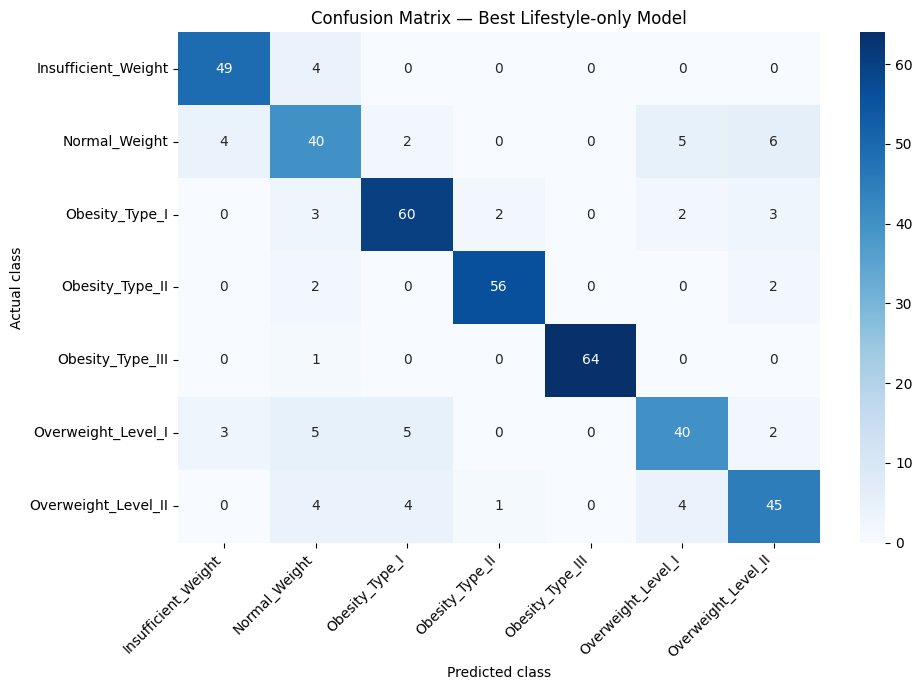

In [7]:
life_predictions = best_life.predict(Xtest_life)

print("Best model:", best_life_name)
print(classification_report(ytest_life, life_predictions, zero_division=0))

labels = sorted(y.unique())
cm = confusion_matrix(ytest_life, life_predictions, labels=labels)
plt.figure(figsize=(10, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=labels, yticklabels=labels)
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.title("Confusion Matrix — Best Lifestyle-only Model")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## 6. Feature importance (Random Forest)
Feature importance is available for the Random Forest pipeline. It indicates model reliance, not cause-and-effect.

,Feature,Importance
0,num__Age,0.149846
1,num__FCVC,0.128939
2,num__NCP,0.089791
4,num__FAF,0.087465
3,num__CH2O,0.084130
5,num__TUE,0.082755
6,cat__Gender_Female,0.037825
7,cat__Gender_Male,0.035688
22,cat__CALC_Sometimes,0.033434
8,cat__family_history_with_overweight_no,0.030973


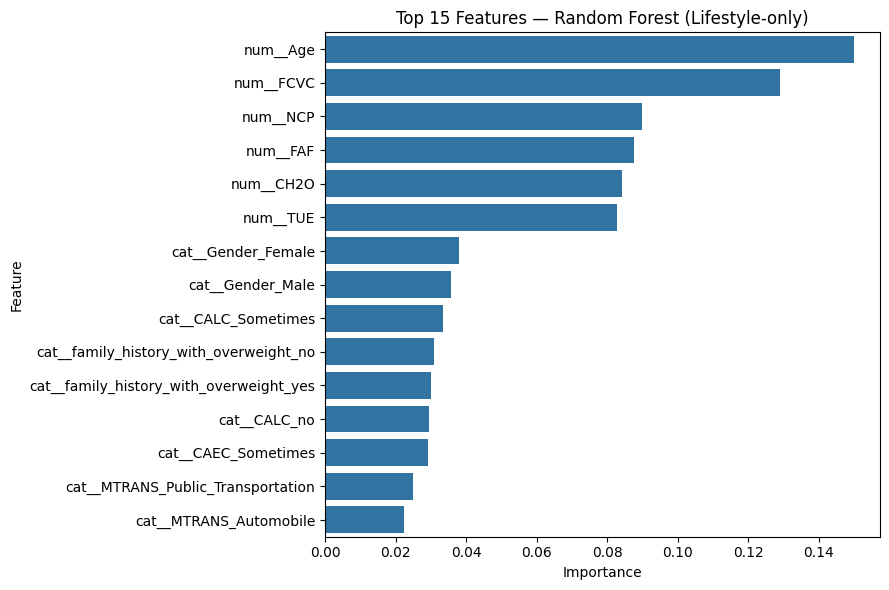

In [8]:
rf_life = models_life["Random Forest"]
feature_names = rf_life.named_steps["preprocessor"].get_feature_names_out()
importances = rf_life.named_steps["classifier"].feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False).head(15)

display(importance_df)
plt.figure(figsize=(9, 6))
sns.barplot(data=importance_df, x="Importance", y="Feature")
plt.title("Top 15 Features — Random Forest (Lifestyle-only)")
plt.tight_layout()
plt.show()

## 7. Enter a person's details and predict
The form below asks for each field present in your dataset. Dropdowns are based on the dataset's observed categories, and numeric fields use typical values from the dataset. The model will predict using the **best lifestyle-only model**, which excludes Height and Weight.

If a column in your CSV is named differently, the code reports it and uses the actual column names detected above.

In [9]:
import ipywidgets as widgets
from IPython.display import display, clear_output

# Build input controls based on the dataset columns, excluding the target and BMI-related fields.
input_columns = X_lifestyle.columns.tolist()
controls = {}

for col in input_columns:
    series = X_lifestyle[col]
    if pd.api.types.is_numeric_dtype(series):
        vals = pd.to_numeric(series, errors="coerce").dropna()
        default = float(vals.median()) if len(vals) else 0.0
        min_val = float(vals.min()) if len(vals) else 0.0
        max_val = float(vals.max()) if len(vals) else 10.0
        # Use a numeric text box so values need not be integers.
        controls[col] = widgets.FloatText(
            value=round(default, 3),
            description=col,
            style={"description_width": "initial"},
            layout=widgets.Layout(width="520px")
        )
    else:
        options = sorted(series.dropna().astype(str).unique().tolist())
        if not options:
            options = [""]
        controls[col] = widgets.Dropdown(
            options=options,
            value=options[0],
            description=col,
            style={"description_width": "initial"},
            layout=widgets.Layout(width="520px")
        )

predict_button = widgets.Button(description="Predict Obesity Level", button_style="success")
output = widgets.Output()

def predict_from_form(_):
    with output:
        clear_output()
        row = {}
        for col in input_columns:
            val = controls[col].value
            # Preserve numeric vs categorical type expected by the pipeline.
            if pd.api.types.is_numeric_dtype(X_lifestyle[col]):
                row[col] = float(val)
            else:
                row[col] = str(val)
        person_df = pd.DataFrame([row], columns=input_columns)
        prediction = best_life.predict(person_df)[0]
        print("Predicted obesity level:", prediction)
        print("\\nModel used:", best_life_name)
        print("Note: This is an educational estimate, not a medical diagnosis.")

predict_button.on_click(predict_from_form)

display(widgets.VBox(list(controls.values()) + [predict_button, output]))

## 8. Optional: save the trained model
The saved bundle includes the selected lifestyle-only pipeline and the expected feature columns.

In [10]:
from joblib import dump

model_bundle = {
    "model": best_life,
    "features": input_columns,
    "target_name": TARGET,
    "model_name": best_life_name
}
dump(model_bundle, "obesity_model_lifestyle_only.joblib")
print("Saved: obesity_model_lifestyle_only.joblib")

# Download the saved model to your computer if needed:
files.download("obesity_model_lifestyle_only.joblib")

Saved: obesity_model_lifestyle_only.joblib


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>